# Long experiment: do tiny rain perturbations separate the runs in the long run?

One year of rain is multiplied by (1 + eps) with eps about 1 % (random, 30 runs). The model is deterministic, so every difference comes from the dynamics. We follow net ecosystem exchange (NEE) for 4580 years (plus 20 unperturbed years before) and ask:

1. Groups: when do runs stop belonging to the same trajectory as the control? (hierarchical clustering of delay-embedded NEE)
2. Correlation: do runs and control stay in phase? (running correlation, members vs. ensemble mean)

Data: `data/p1400_twin_runs_part1.csv` to `_part3.csv` (one table split in three files, joined when loaded), experiment `long_rain` (NEE only, `t` = years after the perturbation).

In [1]:
import os
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import pdist
import plotlib as pl

pl.slide_style()
FIG = "figures/"      # figures are written here
os.makedirs(FIG, exist_ok=True)

## Settings

In [2]:
VARIABLE = "cflux_NEE"                      # net ecosystem exchange (+ = carbon lost)
SECTIONS = [(0, 1000), (4000, 4500)]        # years after the perturbation that are drawn
DIM, LAG = 5, 5                             # state = 5 annual NEE values, 5 years apart (delay embedding)
STEP, CUTOFF = 25, 0.1                      # group every 25 years; runs closer than 10 % of the typical |NEE| are one group
WINDOW, WINDOW_STEP = 500, 100              # running correlation: 500-yr window, 100-yr step

In [3]:
# the data is split in three files (upload size limit); they have the same columns and are joined row-wise
DATA_FILES = ["data/p1400_twin_runs_part1.csv", "data/p1400_twin_runs_part2.csv", "data/p1400_twin_runs_part3.csv"]
df = pd.concat([pd.read_csv(f) for f in DATA_FILES], ignore_index=True)
df = df[df.experiment == "long_rain"]
modes = list(pl.MODE_COLORS)

runs = {}      # runs[mode] = (values, t) with values[run, year] and run 0 = control
for mode in modes:
    wide = df[df["mode"] == mode].pivot(index="member", columns="t", values=VARIABLE)
    runs[mode] = (wide.values, wide.columns.values)
print(df.groupby("mode").member.nunique().rename("runs incl. control"))

mode
A_nofire             31
C_fire_accumulate    31
Name: runs incl. control, dtype: int64


### Why these methods

- Hierarchical clustering (average linkage) groups runs that are still on the same trajectory. Unlike k-means it needs no number of groups in advance, and the number of groups is exactly what we want to measure. The cut is a distance in physical units (10 % of the typical |NEE|), so it has a meaning. 
- Delay embedding: one NEE value does not identify the state of the vegetation (the same NEE occurs while biomass grows and while it falls). A short history (x(t), x(t-5), ..., x(t-20)) of the annual NEE does, which is the idea of Takens.
- Running correlation is a simple measure of whether two runs are still in phase, independent of offset and amplitude. Comparing single runs (r_m) with the ensemble mean (r_e) separates "single runs are lost" from "the ensemble still carries information about the control".

### Limitations

- Cutoff and embedding (5 x 5 years) are choices (and are not motivated here, however one could optimize that with FNN and autocorrelation), and the number of groups depends on them. Clustering is done independently every 25 years, so group labels are not followed through time.
- Only NEE is used. Runs could agree in NEE but differ in biomass or composition.
- Pearson correlation is dominated by large values: in mode C the fire spikes control r. A 500-year window smooths over shorter episodes, and with 30 runs the 10-90 % band rests on about three runs on each side.

## 1. The time series

Black = control, blue = the 30 perturbed runs, orange = their mean. For mode C the y axis is linear between -1 and 1 and logarithmic (base 2) outside, so fire spikes and negative values are both visible.

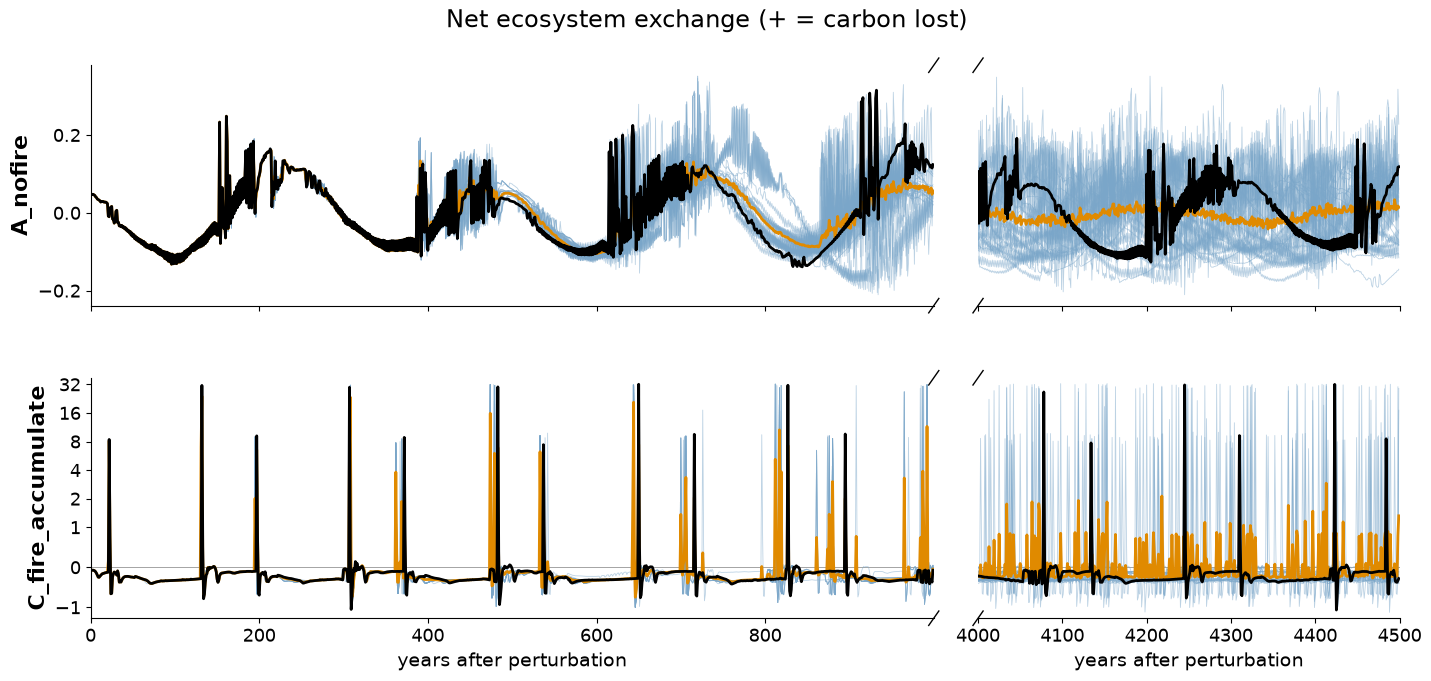

In [4]:
fig = pl.plot_sections(runs, SECTIONS)
fig.savefig(FIG + "sel_cflux_NEE.png", dpi=115)

Why this graph: a spaghetti plot shows every run, so divergence is seen directly and not hidden behind an average. Control (black) and member mean (orange) are drawn on top of the thin, transparent members. The time axis is broken (`//`) to show the early and the late phase at full resolution without 3000 years in between. Mode C uses a symmetric-log y axis because fire spikes are about 30 times larger than normal NEE. The modes are in separate rows, so the orange mean is not confused with the mode C colour.

## 2. Groups over time

Each run is described by a delay embedding of its annual NEE: (x(t), x(t-5), ..., x(t-20)). This gives every run a memory of about 25 years. Runs whose embedded states are closer than the cutoff (RMS distance, in units of the control's mean |NEE|) form one group (average-linkage hierarchical clustering). Group 0 is always the control's group.

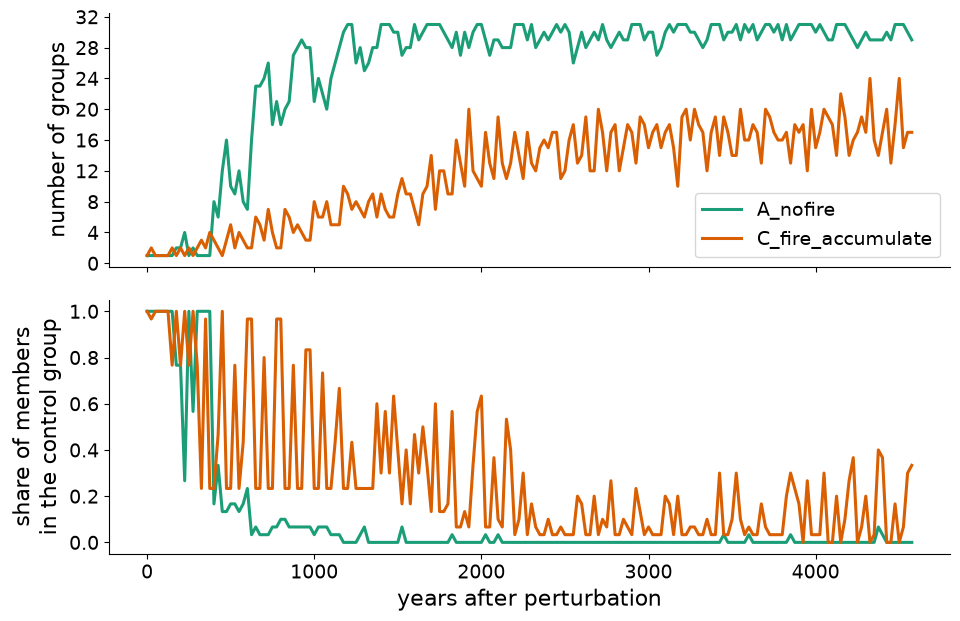

In [5]:
def group_labels(states):
    """Group number per run (states[run, entries], run 0 = control); the others are numbered by size."""
    raw = fcluster(linkage(pdist(states) / np.sqrt(states.shape[1]), method="average"), t=CUTOFF, criterion="distance")
    others = sorted(set(raw) - {raw[0]}, key=lambda g: -np.sum(raw == g))
    renumber = {g: i for i, g in enumerate([raw[0]] + others)}
    return np.array([renumber[g] for g in raw])


def groups_over_time(values, t):
    x = values / np.mean(np.abs(values[0]))                                     # relative to the control's mean |NEE|
    pick = np.arange((DIM - 1) * LAG, x.shape[1], STEP)
    labels = np.array([group_labels(x[:, [j - e * LAG for e in range(DIM)]]) for j in pick])
    return t[pick], labels


group_results = {}
for mode in modes:
    years, labels = groups_over_time(*runs[mode])
    group_results[mode] = (years, labels)
    
fig = pl.plot_groups(group_results)
fig.savefig(FIG + "groups_comparison.png", dpi=110)

Why this graph: two stacked line plots with a shared time axis: the number of groups (how many trajectories exist) and the share of runs still with the control. Both modes are in one panel, in the same colours as notebook 01, to compare them directly. The share has a fixed range of 0 to 1.

## 3. Running correlation

r_m: correlation of every run with the control in a 500-year window, averaged over runs (band: 10-90 % of runs). r_e: correlation of the ensemble mean with the control. r_m near 0 means single runs no longer follow the control. If r_e stays high, the average still carries information about the control.

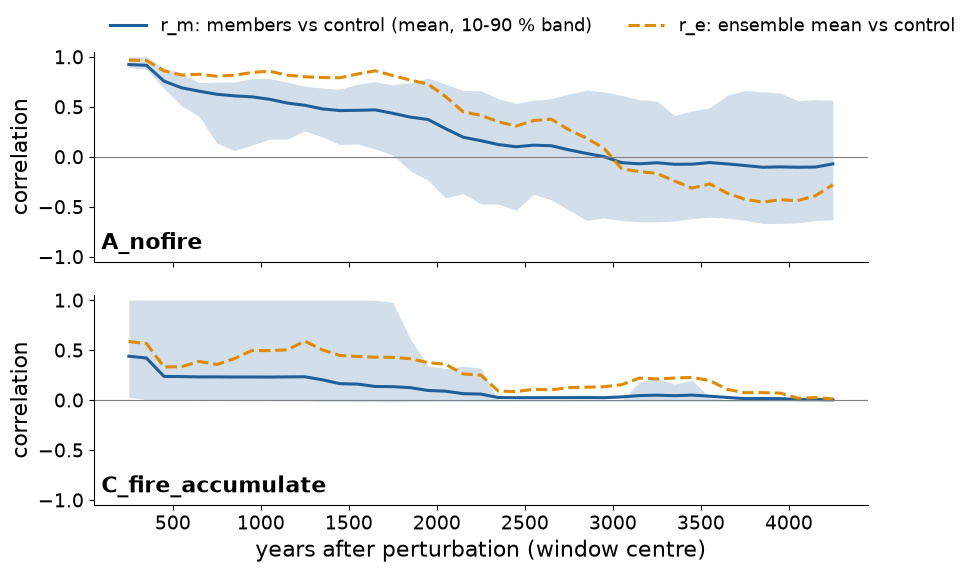

In [6]:
def running_correlation(values, t):
    rows = []
    for start in range(0, t.max() + 2 - WINDOW, WINDOW_STEP):
        m = (t >= start) & (t < start + WINDOW)
        r_members = [np.corrcoef(v[m], values[0][m])[0, 1] for v in values[1:]]
        rows.append({"centre": start + WINDOW / 2,
                     "r_members": np.mean(r_members),
                     "p10": np.percentile(r_members, 10),
                     "p90": np.percentile(r_members, 90),
                     "r_ensemble_mean": np.corrcoef(values[1:].mean(axis=0)[m], values[0][m])[0, 1]})
    return pd.DataFrame(rows)


correlations = {mode: running_correlation(*runs[mode]) for mode in modes}
fig = pl.plot_running_correlation(correlations)
fig.savefig(FIG + "corr_cflux_NEE.png", dpi=115)

Why this graph: one panel per mode with a fixed y range of -1 to 1, so the panels compare. The band shows the spread over runs instead of a single average. r_m and r_e differ in colour and line style (solid/dashed), so they are also distinguishable in greyscale.

## 4. Results in short

- Without fire (A) the runs stay together for about 200-250 years, then split. From year ~400 fewer than half of the runs are still with the control, and at the end every run is on its own trajectory (up to 31 groups = all runs).
- With fire (C) the runs split earlier (share below 50 % from year ~330) but keep re-joining the control for short times. At the end about a third are in the control's group and at most 22 groups exist.
- Single runs lose their correlation with the control over ~3000 years (A), or start low because fire years do not coincide (C). The ensemble mean stays correlated longer (A: r_e about 0.8 until ~1800 years) but not forever.
- So a 1 % change of one year of rain is enough to give a different long-term trajectory: beyond a few centuries, differences between single runs at this cell are internal variability.

## Caveats of the experiment

- One grid cell and one control run. The 30 perturbations all use the same restart state.
- The cutoff 0.1 and the embedding (5 x 5 years) are choices, not results. The number of groups depends on them.